# Prise en main de PyTorch

**Objectifs de la séance.**
- Manipuler les tenseurs PyTorch.
- Comprendre le graphe de calcul et l'autodifférenciation (`requires_grad`, `.backward()`, `.grad`).
- Faire tourner une descente de gradient "à la main" en PyTorch, sur une fonction jouet puis sur une régression linéaire.

In [1]:

import torch
import matplotlib.pyplot as plt

torch.manual_seed(0)


## Partie 1 : Tenseurs

Un tenseur PyTorch ressemble beaucoup à un tableau `numpy` : il a une forme (`shape`), un type (`dtype`), et supporte les opérations usuelles (`+`, `*`, produit matriciel, etc.). La différence essentielle apparaîtra en partie 3 : un tenseur peut « se souvenir » des opérations dont il est issu, ce qui permettra le calcul automatique de gradients.

In [2]:

# Quelques façons de créer des tenseurs
a = torch.tensor([1.0, 2.0, 3.0])
b = torch.zeros(2, 3)
c = torch.ones(3, 2)
d = torch.rand(2, 2)          # tirage uniforme dans [0, 1)
e = torch.arange(0, 10, 2)

for name, t in [("a", a), ("b", b), ("c", c), ("d", d), ("e", e)]:
    print(f"{name}: shape={tuple(t.shape)}, dtype={t.dtype}")
    print(t)
    print()

a: shape=(3,), dtype=torch.float32
tensor([1., 2., 3.])

b: shape=(2, 3), dtype=torch.float32
tensor([[0., 0., 0.],
        [0., 0., 0.]])

c: shape=(3, 2), dtype=torch.float32
tensor([[1., 1.],
        [1., 1.],
        [1., 1.]])

d: shape=(2, 2), dtype=torch.float32
tensor([[0.4963, 0.7682],
        [0.0885, 0.1320]])

e: shape=(5,), dtype=torch.int64
tensor([0, 2, 4, 6, 8])




**Question 1.1.** Le *broadcasting* permet d'effectuer des opérations entre tenseurs de formes différentes, à condition qu'elles soient « compatibles » (comme en `numpy`). Avant d'exécuter la cellule ci-dessous, essayez de prédire la forme du résultat de `x + y` pour chacune des trois paires proposées.

In [3]:

x1, y1 = torch.rand(3, 1), torch.rand(1, 4)
x2, y2 = torch.rand(5, 3), torch.rand(3)
x3, y3 = torch.rand(2, 1, 4), torch.rand(3, 1)

for x, y in [(x1, y1), (x2, y2), (x3, y3)]:
    z = x + y
    print(f"{tuple(x.shape)} + {tuple(y.shape)} -> {tuple(z.shape)}")

(3, 1) + (1, 4) -> (3, 4)
(5, 3) + (3,) -> (5, 3)
(2, 1, 4) + (3, 1) -> (2, 3, 4)



**Question 1.2.** Créez un tenseur `m` de forme `(4, 5)` rempli de valeurs tirées selon une loi normale centrée réduite (indice : [`torch.randn`](https://docs.pytorch.org/docs/stable/generated/torch.randn.html)), puis un vecteur `v` de forme `(5,)` rempli de 1. Calculez `m + v` et vérifiez que la forme du résultat est bien `(4, 5)`.

In [4]:
m = torch.randn(4, 5)
v = torch.ones(5)
result = m + v
print("m.shape =", tuple(m.shape))
print("v.shape =", tuple(v.shape))
print("(m + v).shape =", tuple(result.shape))
print(result)

m.shape = (4, 5)
v.shape = (5,)
(m + v).shape = (4, 5)
tensor([[ 0.7841,  0.2575,  1.5627,  1.2596,  1.5943],
        [ 2.5419,  1.5073,  0.4090,  0.4308,  1.9200],
        [ 2.1108,  2.2899, -0.4959,  0.8062,  1.4455],
        [ 2.3253, -0.6293,  0.4503,  0.5202,  0.5003]])



## Partie 2 : Différentiation manuelle en Python

Avant de nous appuyer sur PyTorch et l'autodifférenciation, voyons comment on ferait de la différentiation manuelle en Python pur.

On prend un exemple très simple en 1D : soit $x$ un scalaire et $y$ défini par

$$y = (x - 0.5)^2$$

L'objectif est de trouver la valeur de $x$ qui minimise $y$.

**Question 2.1.** Définissez une fonction `f` qui prend `x` en entrée et renvoie $y = (x-0.5)^2$.

In [5]:
def f(x):
    return (x - 0.5) ** 2


Pour minimiser $y$, on va utiliser une descente de gradient : on met à jour $x$ itérativement en le déplaçant dans la direction opposée au gradient $\frac{\partial y}{\partial x}$. Il nous faut donc être capable de calculer $\frac{\partial y}{\partial x}$, et comme on n'utilise pas encore l'autodifférenciation, il faut fournir la formule explicite de cette dérivée.

**Question 2.2.** Définissez une fonction `grad_f` qui prend `x` en entrée et renvoie $\frac{\partial y}{\partial x}$.

In [6]:
def grad_f(x):
    return 2 * (x - 0.5)


La règle de mise à jour de la descente de gradient s'écrit :

$$x \leftarrow x - \rho \frac{\partial y}{\partial x}$$

où $\rho$ (`rho`) est le pas d'apprentissage (*learning rate*).

**Question 2.3.** Choisissez une valeur de départ pour `x` et un pas `rho`, puis appliquez 30 itérations de descente de gradient (en utilisant `grad_f`). Affichez `x` à chaque itération.

In [7]:
x = 0.0
rho = 0.1

for i in range(30):
    print(i, x)
    x = x - rho * grad_f(x)

print("x final :", x)

0 0.0
1 0.1
2 0.18000000000000002
3 0.244
4 0.2952
5 0.33616
6 0.36892800000000003
7 0.3951424
8 0.41611392
9 0.432891136
10 0.4463129088
11 0.45705032704000004
12 0.465640261632
13 0.4725122093056
14 0.47800976744448
15 0.48240781395558396
16 0.4859262511644672
17 0.48874100093157374
18 0.490992800745259
19 0.4927942405962072
20 0.49423539247696574
21 0.49538831398157257
22 0.4963106511852581
23 0.49704852094820645
24 0.49763881675856514
25 0.49811105340685213
26 0.4984888427254817
27 0.4987910741803854
28 0.4990328593443083
29 0.4992262874754466
x final : 0.49938102998035727



**Question 2.4.** La valeur de `x` obtenue est-elle proche de celle attendue (le minimiseur de $y=f(x)$) ?

_Le minimiseur de $y=(x-0.5)^2$ est $x=0.5$ : la valeur obtenue par descente de gradient s'en rapproche bien (à `rho` et nombre d'itérations suffisants), puisque la fonction est convexe et que 0.5 est l'unique point où $\frac{\partial y}{\partial x}=0$._


## Partie 3 : Calcul automatique de gradients avec `autograd`

PyTorch ressemble beaucoup à `numpy`, à un détail près : on peut à tout moment demander le calcul automatique de gradients. Pour cela, il faut :

1. créer les tenseurs concernés avec `requires_grad=True` ;
2. calculer la quantité dont on veut le gradient (ex. `y = f(x)`) ;
3. appeler `y.backward()` : PyTorch calcule alors $\frac{\partial y}{\partial b}$ pour **tout** tenseur `b` ayant contribué au calcul de `y` (à condition que `b.requires_grad` soit `True`) ;
4. lire le résultat dans `b.grad`.

**Question 3.1.** Complétez le code ci-dessous pour calculer $y = f(x)$ avec $x = 0.125$, puis affichez `x.grad` *avant* d'avoir appelé `.backward()` : que vaut-il ?

In [8]:
def f(x):
    return (x - 0.5) ** 2

x = torch.tensor(0.125, requires_grad=True)

# TODO : calculer y
y = f(x)

print(x.grad)

None



**Question 3.2.** Déclenchez maintenant le calcul du gradient $\frac{\partial y}{\partial x}$ (via `.backward()`) et affichez-le. Vérifiez qu'il correspond à ce que donnerait `grad_f(x)` de la partie 2.

In [9]:
y.backward()
print(x.grad)

tensor(-0.7500)



**Question 3.3.** Que se passe-t-il si vous encapsulez le calcul de `y` dans un bloc `with torch.no_grad():` ? Exécutez le code ci-dessous et regardez l'attribut `y.requires_grad`.

In [10]:

x = torch.tensor(0.125, requires_grad=True)

with torch.no_grad():
    y = f(x)

print("y.requires_grad :", y.requires_grad)

y.requires_grad : False



## Partie 4 : Descente de gradient en PyTorch

**Question 4.1.** Reprenez la descente de gradient de la partie 2, mais en PyTorch cette fois : vous n'avez plus besoin de `grad_f`, autograd s'en charge. Chaque itération doit :

1. calculer `y` à partir de la valeur courante de `x` ;
2. déclencher le calcul du gradient ;
3. mettre à jour `x` (cette étape doit être protégée par `with torch.no_grad():`, sinon la mise à jour elle-même serait enregistrée dans le graphe de calcul) ;
4. remettre `x.grad` à zéro pour l'itération suivante (sans quoi PyTorch **accumule** les gradients au lieu de les remplacer, ligne déjà fournie ci-dessous).

In [11]:
x = torch.tensor(0.125, requires_grad=True)

rho = 0.1
n_iter = 30

for i in range(n_iter):
    print(i, x.item())
    # TODO : calculer y et déclencher le calcul du gradient
    y = f(x)
    y.backward()

    with torch.no_grad():
        x -= rho * x.grad  # TODO : mettre à jour x

    x.grad.zero_()  # ne pas modifier : remise à zéro du gradient

0 0.125
1 0.20000000298023224
2 0.25999999046325684
3 0.30799999833106995
4 0.3463999927043915
5 0.3771199882030487
6 0.40169599652290344
7 0.42135679721832275
8 0.43708544969558716
9 0.44966834783554077
10 0.4597346782684326
11 0.4677877426147461
12 0.47423020005226135
13 0.4793841540813446
14 0.48350733518600464
15 0.48680585622787476
16 0.48944467306137085
17 0.49155575037002563
18 0.49324458837509155
19 0.4945956766605377
20 0.49567654728889465
21 0.49654123187065125
22 0.49723297357559204
23 0.49778637290000916
24 0.49822908639907837
25 0.49858325719833374
26 0.49886661767959595
27 0.49909329414367676
28 0.4992746412754059
29 0.4994197189807892



## Partie 5 : Pour aller plus loin : une régression linéaire

On termine cette séance en démarrant un exercice qui sera repris et terminé en séance 2 : ajuster un modèle de régression linéaire univarié $\hat y = wX + b$ à un jeu de données synthétique, par descente de gradient.

Le code ci-dessous génère et affiche le jeu de données (ne le modifiez pas : vous le retrouverez à l'identique en séance 2).

Text(0, 0.5, 'y')

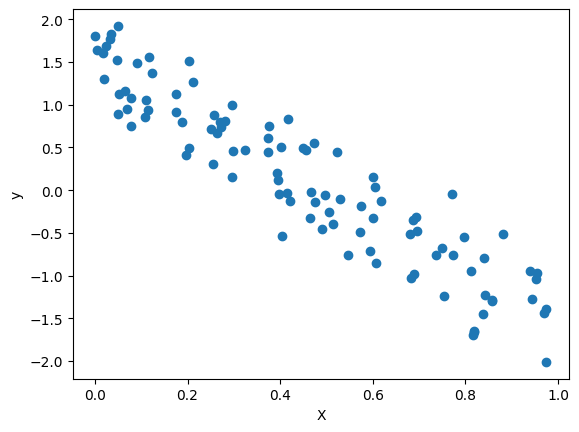

In [12]:

X = torch.rand(100, 1)
# w* = -3, b* = 1.5
y = -3.0 * X + 1.5 + 0.4 * torch.randn(X.size())

plt.scatter(X.numpy(), y.numpy())
plt.xlabel("X"); plt.ylabel("y")


**Question 5.1.** D'après la façon dont le jeu de données a été généré, quelles devraient être les valeurs idéales de $w$ et $b$ ?

_D'après la génération des données ($y = -3X + 1.5 + \text{bruit}$), les valeurs idéales sont $w=-3$ et $b=1.5$._


**Question 5.2.** Implémentez une fonction `mse(X, y, w, b)` qui calcule l'erreur quadratique moyenne du modèle linéaire $\hat y = wX + b$ sur le jeu de données $(X, y)$.

In [13]:
def mse(X, y, w, b):
    y_pred = w * X + b
    return torch.mean((y_pred - y) ** 2)


**Question 5.3.** Initialisez `w` et `b` (tenseurs scalaires, `requires_grad=True`), puis écrivez une boucle de descente de gradient : à chaque itération, calculez la perte `mse`, déclenchez le calcul des gradients, mettez à jour `w` et `b` avec un pas `rho = 0.1`, puis remettez les gradients à zéro. Faites tourner une trentaine d'itérations en affichant la perte toutes les 5 itérations pour vérifier qu'elle diminue.

In [14]:
w = torch.tensor(0.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

rho = 0.1
n_iter = 30

for i in range(n_iter):
    # TODO : calculer la perte
    err = mse(X, y, w, b)

    # TODO : déclencher le calcul des gradients
    err.backward()

    with torch.no_grad():
        w -= rho * w.grad  # TODO : mettre à jour w et b
        b -= rho * b.grad

    # TODO : remettre w.grad et b.grad à zéro
    w.grad.zero_()
    b.grad.zero_()

    if i % 5 == 0:
        print(i, err.item())  # TODO : afficher la perte courante

0 0.9524114727973938
5 0.8438211679458618
10 0.7497013211250305
15 0.6679161190986633
20 0.5968365669250488
25 0.5350602865219116



## Bilan

Vous savez maintenant créer des tenseurs, calculer des gradients automatiquement, et coder une boucle de descente de gradient en PyTorch.